# Задание 1. Функции активации и инициализация весов

**Цель.** Исследовать, как выбор активации и распределения начальных весов влияет на сигнал прямого прохода, величину градиентов и обучение многослойной сети.

Рассматриваются ReLU, Tanh, Identity и LeakyReLU (дополнительная активация). Для каждого варианта используются четыре способа инициализации: нулевая, нормальная, Xavier и Kaiming. Сначала проводятся измерения на одном и том же батче, затем сравнивается обучение моделей на FashionMNIST с SGD.

Стандартное отклонение выходов слоя характеризует масштаб активаций. Стандартное отклонение производных функции потерь по выходам слоя характеризует масштаб передаваемого назад градиента. При интерпретации оба показателя нужно рассматривать совместно: практически нулевой сигнал может означать вырождение, а резкий рост — нестабильность.

In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
BATCH_SIZE = 256
TRAIN_LIMIT = 12000
VALID_LIMIT = 3000
EPOCHS = 3
LEARNING_RATE = 0.05
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.2})
print(f"Устройство: {DEVICE}; PyTorch: {torch.__version__}")

Устройство: cpu; PyTorch: 2.14.1+cpu


## 1. Данные

FashionMNIST состоит из изображений одежды размером 28 × 28 и десяти классов. Датасет скачивается автоматически при первом запуске. Для ускорения экспериментов используется фиксированное подмножество; размеры можно изменить в начале ноутбука.

In [3]:
def find_dataset_directory():
    roots = [Path.cwd(), Path.cwd().parent, Path.cwd() / "homeworks",
             Path.cwd().parent / "homeworks"]
    for root in roots:
        if (root / "01_activations").is_dir():
            return root / "data" / "fashion_mnist"
    return Path.cwd() / "data" / "fashion_mnist"

DATA_DIR = find_dataset_directory()
transform = transforms.ToTensor()
train_source = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=transform)
valid_source = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=transform)

def get_loader(dataset, limit, shuffle):
    indices = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(SEED))[:min(limit, len(dataset))].tolist()
    subset = Subset(dataset, indices)
    return DataLoader(subset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      generator=torch.Generator().manual_seed(SEED), num_workers=0)

train_loader = get_loader(train_source, TRAIN_LIMIT, True)
valid_loader = get_loader(valid_source, VALID_LIMIT, False)
x_probe, y_probe = next(iter(valid_loader))
print(f"Обучение: {len(train_loader.dataset):,}; проверка: {len(valid_loader.dataset):,}; пример: {tuple(x_probe.shape)}")

100%|██████████| 26.4M/26.4M [00:16<00:00, 1.59MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 589kB/s]
100%|██████████| 4.42M/4.42M [00:03<00:00, 1.44MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 7.46MB/s]


Обучение: 12,000; проверка: 3,000; пример: (256, 1, 28, 28)


## 2. Архитектура сети

Используется заданная полносвязная сеть с размерами скрытых слоёв 512, 256, 256 и 128. Каждый линейный слой, кроме последнего, сопровождается выбранной активацией. Выходной слой возвращает логиты десяти классов.

In [4]:
class BaseNetwork(nn.Module):
    def __init__(self, act_fn, input_size=784, num_classes=10, hidden_sizes=(512, 256, 256, 128)):
        super().__init__()
        layers = []
        sizes = [input_size, *hidden_sizes]
        for index in range(1, len(sizes)):
            layers.extend([nn.Linear(sizes[index - 1], sizes[index]), act_fn])
        layers.append(nn.Linear(sizes[-1], num_classes))
        self.layers = nn.ModuleList(layers)
        self.config = {
            "act_fn": type(act_fn).__name__,
            "input_size": input_size,
            "num_classes": num_classes,
            "hidden_sizes": list(hidden_sizes),
        }

    def forward(self, x):
        x = x.view(x.size(0), -1)
        for layer in self.layers:
            x = layer(x)
        return x

ACTIVATIONS = {
    "ReLU": nn.ReLU,
    "Tanh": nn.Tanh,
    "Identity": nn.Identity,
    "LeakyReLU": lambda: nn.LeakyReLU(negative_slope=0.1),
}
INITIALIZATIONS = ["Zero", "Normal", "Xavier", "Kaiming"]

def initialize_weights(model, method):
    for layer in model.modules():
        if not isinstance(layer, nn.Linear):
            continue
        if method == "Zero":
            nn.init.constant_(layer.weight, 0.0)
        elif method == "Normal":
            nn.init.normal_(layer.weight, mean=0.0, std=0.05)
        elif method == "Xavier":
            nn.init.xavier_uniform_(layer.weight)
        elif method == "Kaiming":
            nn.init.kaiming_normal_(layer.weight, mode="fan_in", nonlinearity="relu")
        else:
            raise ValueError(f"Неизвестная инициализация: {method}")
        nn.init.zeros_(layer.bias)
    return model

model_check = BaseNetwork(nn.ReLU())
assert model_check(torch.zeros(2, 1, 28, 28)).shape == (2, 10)
print(model_check.config)

{'act_fn': 'ReLU', 'input_size': 784, 'num_classes': 10, 'hidden_sizes': [512, 256, 256, 128]}


## 3. Активации и градиенты по слоям

Сохраняются выходы **всех** девяти модулей: пяти `Linear` и четырёх активаций. После вычисления `CrossEntropyLoss` выполняется обратный проход. Затем для выходов каждого модуля фиксируются среднее и стандартное отклонение активаций, а также норма и стандартное отклонение их градиентов.

Для сопоставимости все эксперименты используют один батч и одинаковый seed. Значения градиентов относятся к одной функции потерь и одному батчу; это диагностический эксперимент, а не измерение качества обучения.

In [5]:
def layer_statistics(activation_name, initialization, images, targets):
    torch.manual_seed(SEED)
    model = initialize_weights(BaseNetwork(ACTIVATIONS[activation_name]()).to(DEVICE), initialization)
    images = images.to(DEVICE)
    targets = targets.to(DEVICE)
    outputs = []
    model.zero_grad(set_to_none=True)
    logits = images.view(images.size(0), -1)
    for layer in model.layers:
        logits = layer(logits)
        logits.retain_grad()
        outputs.append(logits)
    loss = F.cross_entropy(logits, targets)
    loss.backward()
    rows = []
    for index, (layer, output) in enumerate(zip(model.layers, outputs), start=1):
        rows.append({
            "activation": activation_name,
            "initialization": initialization,
            "layer_index": index,
            "layer": f"{index}: {type(layer).__name__}",
            "activation_mean": output.detach().mean().item(),
            "activation_std": output.detach().std(unbiased=False).item(),
            "gradient_std": output.grad.detach().std(unbiased=False).item(),
            "gradient_norm": output.grad.detach().norm().item(),
            "activation_values": output.detach().reshape(-1)[:3000].cpu().numpy().copy(),
            "gradient_values": output.grad.detach().reshape(-1)[:3000].cpu().numpy().copy(),
        })
    assert len(rows) == len(model.layers)
    return rows

probe_rows = [row for name in ACTIVATIONS for init in INITIALIZATIONS
              for row in layer_statistics(name, init, x_probe, y_probe)]
probe = pd.DataFrame(probe_rows)
probe[["activation", "initialization", "layer", "activation_std", "gradient_std"]].head(12)

,activation,initialization,layer,activation_std,gradient_std
0,ReLU,Zero,1: Linear,0.000000,0.000000
1,ReLU,Zero,2: ReLU,0.000000,0.000000
2,ReLU,Zero,3: Linear,0.000000,0.000000
3,ReLU,Zero,4: ReLU,0.000000,0.000000
4,ReLU,Zero,5: Linear,0.000000,0.000000
5,ReLU,Zero,6: ReLU,0.000000,0.000000
6,ReLU,Zero,7: Linear,0.000000,0.000000
7,ReLU,Zero,8: ReLU,0.000000,0.000000
8,ReLU,Zero,9: Linear,0.000000,0.001172
9,ReLU,Normal,1: Linear,0.641665,0.000016


### Оценка сохранения масштаба сигнала

Для компактного сравнения вычислим отношения стандартных отклонений между первым и последним скрытыми слоями. В этой работе ориентировочно назовём сигнал стабильным, если оба отношения находятся в диапазоне от 0.1 до 10 и не вырождаются в нуль. Это **эвристический критерий**, а не строгая гарантия устойчивости обучения.

In [6]:
stability_rows = []
for activation_name in ACTIVATIONS:
    for initialization in INITIALIZATIONS:
        hidden = probe[(probe.activation == activation_name) &
                       (probe.initialization == initialization) &
                       (probe.layer_index.isin([2, 4, 6, 8]))].sort_values("layer_index")
        first, last = hidden.iloc[0], hidden.iloc[-1]
        ratio_activation = last.activation_std / max(first.activation_std, 1e-15)
        ratio_gradient = first.gradient_std / max(last.gradient_std, 1e-15)
        stable = (first.activation_std > 1e-10 and last.activation_std > 1e-10 and
                  first.gradient_std > 1e-15 and last.gradient_std > 1e-15 and
                  0.1 <= ratio_activation <= 10 and 0.1 <= ratio_gradient <= 10)
        stability_rows.append({"activation": activation_name,
                               "initialization": initialization,
                               "activation_ratio": ratio_activation,
                               "gradient_ratio": ratio_gradient,
                               "stable_by_criterion": stable})
stability = pd.DataFrame(stability_rows)
display(stability.round(4))

,activation,initialization,activation_ratio,gradient_ratio,stable_by_criterion
0,ReLU,Zero,0.0000,0.0000,False
1,ReLU,Normal,0.2673,0.1218,True
2,ReLU,Xavier,0.4998,0.2499,True
3,ReLU,Kaiming,1.0441,0.4769,True
4,Tanh,Zero,0.0000,0.0000,False
5,Tanh,Normal,0.4820,0.2596,True
6,Tanh,Xavier,0.8401,0.4651,True
7,Tanh,Kaiming,1.1052,0.6703,True
8,Identity,Zero,0.0000,0.0000,False
9,Identity,Normal,0.6679,0.3535,True


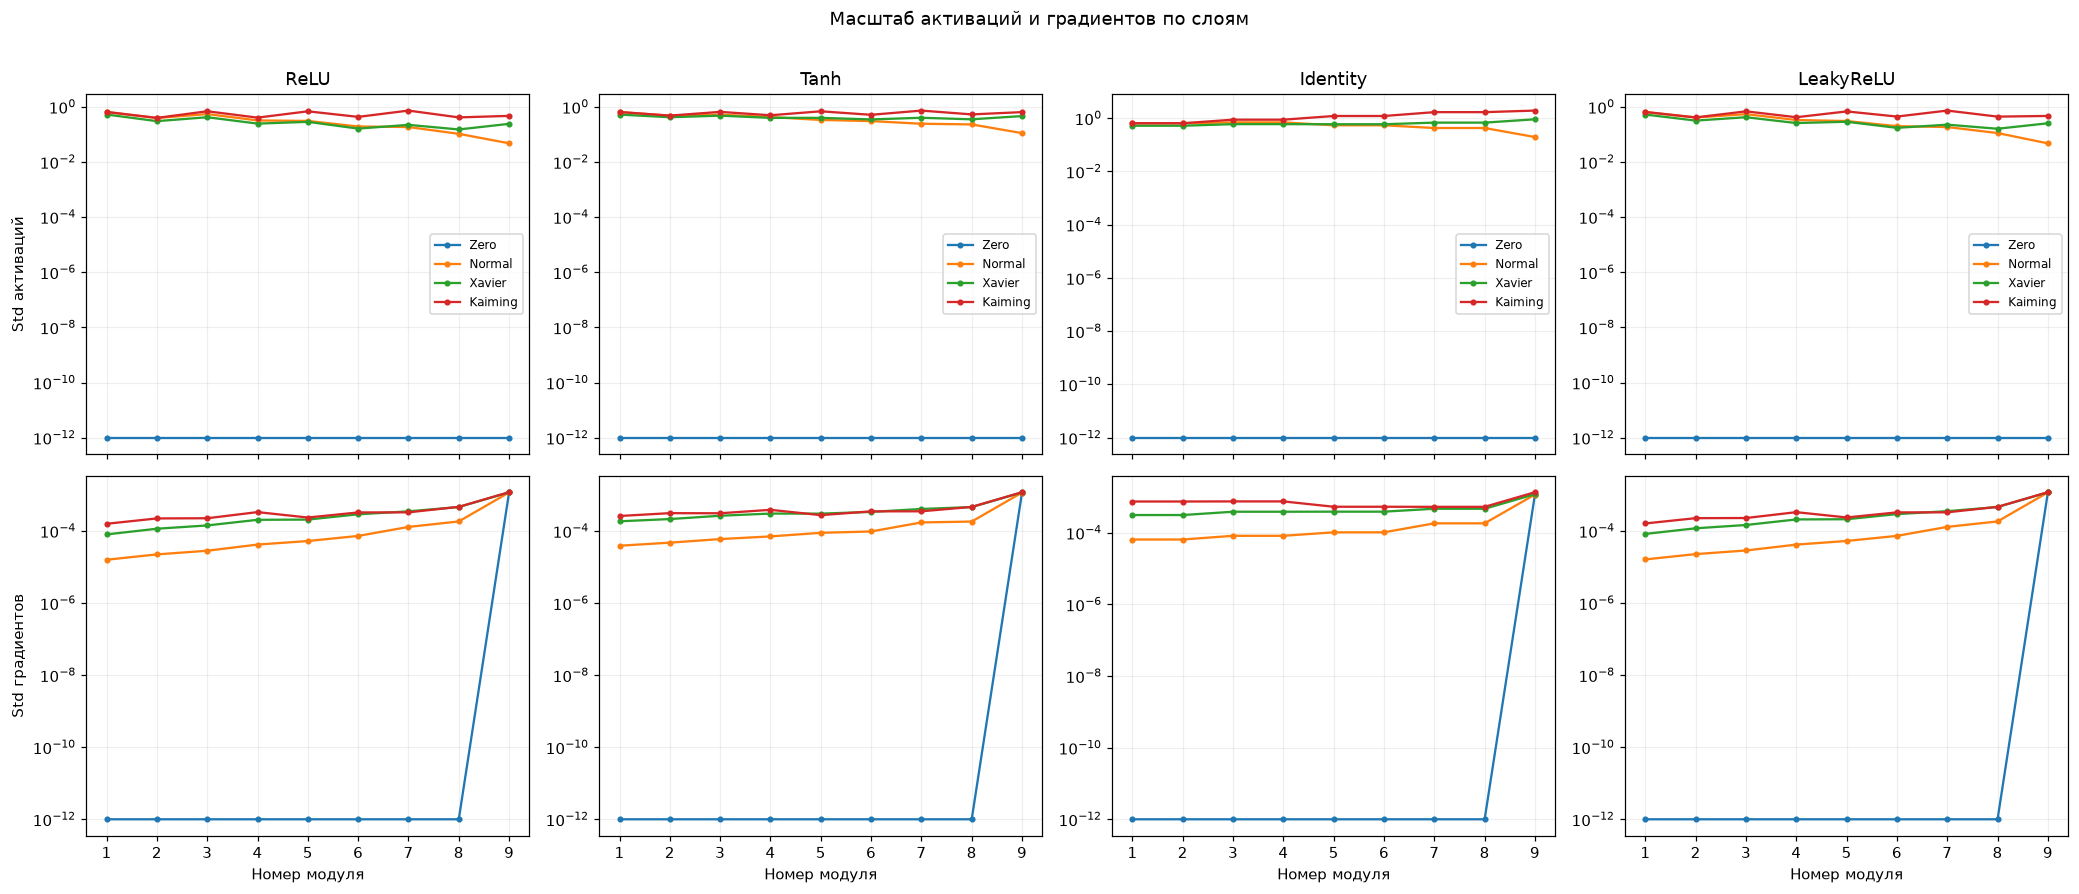

In [7]:
fig, axes = plt.subplots(2, len(ACTIVATIONS), figsize=(19, 8), sharex=True)
for col, name in enumerate(ACTIVATIONS):
    for init in INITIALIZATIONS:
        sample = probe[(probe.activation == name) & (probe.initialization == init)]
        axes[0, col].plot(sample.layer_index, np.maximum(sample.activation_std, 1e-12),
                          marker="o", markersize=3, label=init)
        axes[1, col].plot(sample.layer_index, np.maximum(sample.gradient_std, 1e-12),
                          marker="o", markersize=3, label=init)
    axes[0, col].set_title(name)
    axes[0, col].set_yscale("log")
    axes[1, col].set_yscale("log")
    axes[1, col].set_xlabel("Номер модуля")
    axes[1, col].set_xticks(range(1, 10))
    if col == 0:
        axes[0, col].set_ylabel("Std активаций")
        axes[1, col].set_ylabel("Std градиентов")
    axes[0, col].legend(fontsize=8)
fig.suptitle("Масштаб активаций и градиентов по слоям", y=1.01)
plt.tight_layout()
plt.show()

### Распределения на глубоких слоях

Кроме среднего масштаба полезно посмотреть на форму распределений. На следующем рисунке показаны значения на выходе предпоследнего модуля (активация перед финальным классификатором) и соответствующие градиенты. Для сравнения взяты Xavier и Kaiming.

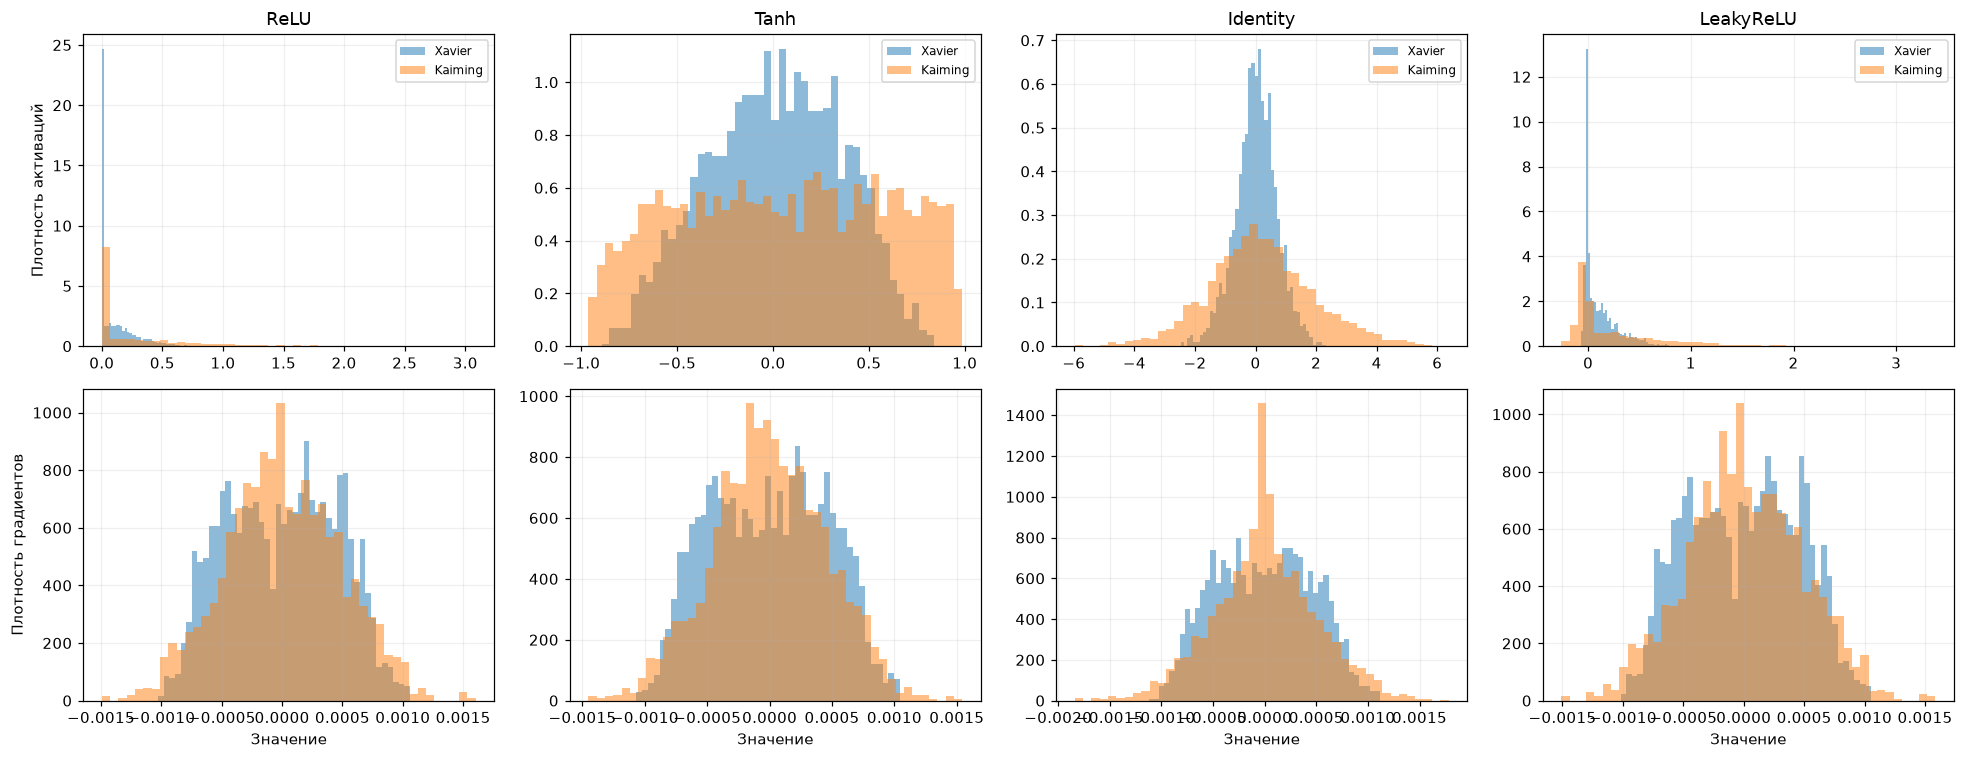

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for col, name in enumerate(ACTIVATIONS):
    for init in ("Xavier", "Kaiming"):
        item = probe[(probe.activation == name) & (probe.initialization == init) & (probe.layer_index == 8)].iloc[0]
        axes[0, col].hist(item.activation_values, bins=45, density=True, alpha=0.5, label=init)
        axes[1, col].hist(item.gradient_values, bins=45, density=True, alpha=0.5, label=init)
    axes[0, col].set_title(name)
    axes[0, col].legend(fontsize=8)
    axes[1, col].set_xlabel("Значение")
axes[0, 0].set_ylabel("Плотность активаций")
axes[1, 0].set_ylabel("Плотность градиентов")
plt.tight_layout()
plt.show()

## 4. Сходимость SGD на FashionMNIST

Для всех сочетаний используется один и тот же оптимизатор SGD с фиксированной скоростью обучения, одинаковое число эпох и одна последовательность батчей. При этом сравниваются `train loss`, `validation loss` и `validation accuracy`. Нулевая инициализация включена как намеренно неудачный контрольный вариант.

In [9]:
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    seen = 0
    with torch.inference_mode():
        for images, target in loader:
            images, target = images.to(DEVICE), target.to(DEVICE)
            prediction = model(images)
            total_loss += F.cross_entropy(prediction, target, reduction="sum").item()
            correct += (prediction.argmax(dim=1) == target).sum().item()
            seen += target.numel()
    return total_loss / seen, correct / seen

def train_sgd(activation_name, initialization):
    torch.manual_seed(SEED)
    model = initialize_weights(BaseNetwork(ACTIVATIONS[activation_name]()).to(DEVICE), initialization)
    optimizer = torch.optim.SGD(model.parameters(), lr=LEARNING_RATE)
    history = []
    local_loader = DataLoader(train_loader.dataset, batch_size=BATCH_SIZE, shuffle=True,
                              generator=torch.Generator().manual_seed(SEED), num_workers=0)
    diverged = False
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        seen = 0
        if not diverged:
            for images, target in local_loader:
                images, target = images.to(DEVICE), target.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                loss = F.cross_entropy(model(images), target)
                if not torch.isfinite(loss):
                    diverged = True
                    break
                loss.backward()
                optimizer.step()
                count = target.numel()
                loss_sum += loss.item() * count
                seen += count
        if diverged:
            val_loss, val_accuracy = float("nan"), float("nan")
        else:
            val_loss, val_accuracy = evaluate(model, valid_loader)
        history.append({"activation": activation_name, "initialization": initialization,
                        "epoch": epoch, "train_loss": loss_sum / max(seen, 1) if not diverged else float("nan"),
                        "val_loss": val_loss, "val_accuracy": val_accuracy})
    return history

history_rows = []
for activation_name in ACTIVATIONS:
    for initialization in INITIALIZATIONS:
        result = train_sgd(activation_name, initialization)
        history_rows.extend(result)
        print(f"{activation_name:10s} {initialization:8s}: accuracy={result[-1]['val_accuracy']:.3f}")
history = pd.DataFrame(history_rows)

ReLU       Zero    : accuracy=0.104
ReLU       Normal  : accuracy=0.628
ReLU       Xavier  : accuracy=0.741
ReLU       Kaiming : accuracy=0.764
Tanh       Zero    : accuracy=0.104
Tanh       Normal  : accuracy=0.725
Tanh       Xavier  : accuracy=0.794
Tanh       Kaiming : accuracy=0.803
Identity   Zero    : accuracy=0.104
Identity   Normal  : accuracy=0.737
Identity   Xavier  : accuracy=0.766
Identity   Kaiming : accuracy=nan
LeakyReLU  Zero    : accuracy=0.104
LeakyReLU  Normal  : accuracy=0.627
LeakyReLU  Xavier  : accuracy=0.735
LeakyReLU  Kaiming : accuracy=0.786


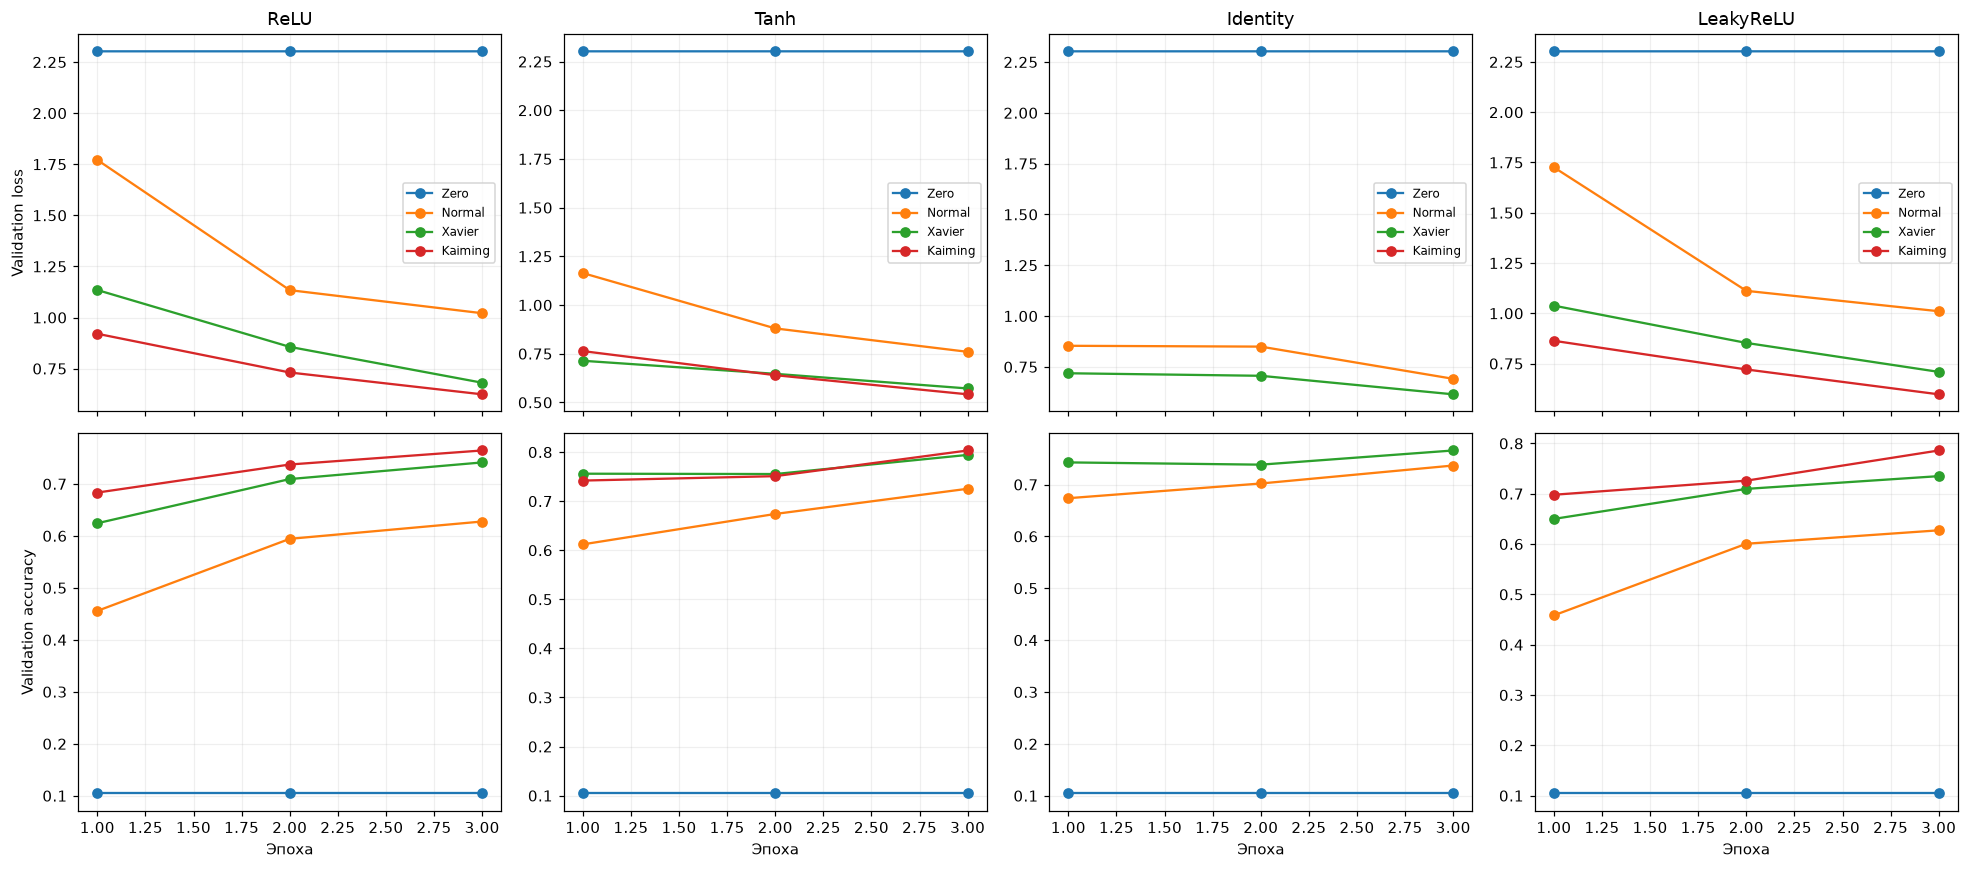

,activation,initialization,train_loss,val_loss,val_accuracy
0,Tanh,Kaiming,0.5369,0.5415,0.8033
1,Tanh,Xavier,0.5683,0.5717,0.7943
2,LeakyReLU,Kaiming,0.6315,0.5973,0.7860
3,Identity,Xavier,0.6033,0.6150,0.7657
4,ReLU,Kaiming,0.6337,0.6241,0.7643
5,ReLU,Xavier,0.7153,0.6809,0.7413
6,Identity,Normal,0.6861,0.6912,0.7367
7,LeakyReLU,Xavier,0.7016,0.7089,0.7350
8,Tanh,Normal,0.8039,0.7597,0.7253
9,ReLU,Normal,0.9974,1.0210,0.6277


In [10]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
for col, activation_name in enumerate(ACTIVATIONS):
    for init in INITIALIZATIONS:
        part = history[(history.activation == activation_name) & (history.initialization == init)]
        axes[0, col].plot(part.epoch, part.val_loss, marker="o", label=init)
        axes[1, col].plot(part.epoch, part.val_accuracy, marker="o", label=init)
    axes[0, col].set_title(activation_name)
    axes[1, col].set_xlabel("Эпоха")
    axes[0, col].legend(fontsize=8)
    if col == 0:
        axes[0, col].set_ylabel("Validation loss")
        axes[1, col].set_ylabel("Validation accuracy")
plt.tight_layout()
plt.show()

summary = (history.sort_values("epoch")
           .groupby(["activation", "initialization"], as_index=False)
           .tail(1)[["activation", "initialization", "train_loss", "val_loss", "val_accuracy"]]
           .sort_values("val_accuracy", ascending=False).reset_index(drop=True))
display(summary.round(4))

## 5. Выводы

Инициализация Xavier ориентирована на сохранение масштаба сигнала в глубоких сетях, особенно для симметричных активаций. Kaiming учитывает обнуление части сигнала после ReLU. При нулевой инициализации нейроны одного слоя остаются симметричными, из-за чего скрытые представления не могут полноценно сформироваться. Identity оставляет всю сеть линейным преобразованием независимо от числа линейных слоёв.

Эти ожидания необходимо сопоставить с измерениями: в данном эксперименте они зависят от выбранной архитектуры, данных, функции потерь и скорости обучения. Следующая ячейка выводит лидирующие сочетания для фактически полученных результатов.

In [11]:
winners = summary.sort_values("val_accuracy", ascending=False).head(5)
print("Лучшие варианты по точности на проверочной выборке:")
for _, row in winners.iterrows():
    print(f"{row['activation']} + {row['initialization']}: {row['val_accuracy']:.2%}")
print("Сравнение на обучении выполнено по", EPOCHS, "эпохам и", len(train_loader.dataset), "изображениям.")

Лучшие варианты по точности на проверочной выборке:
Tanh + Kaiming: 80.33%
Tanh + Xavier: 79.43%
LeakyReLU + Kaiming: 78.60%
Identity + Xavier: 76.57%
ReLU + Kaiming: 76.43%
Сравнение на обучении выполнено по 3 эпохам и 12000 изображениям.
